# Soft-Voting Ensemble — GSE68086 (patched for new dataset)

**Những gì đã sửa so với bản gốc:**
1. Cài thêm các thư viện không có sẵn trên Colab-mặc-định (`xgboost`, `lightgbm`, `catboost`, `imbalanced-learn`, `shap`, `mygene`).
2. Đường dẫn dữ liệu đổi từ ổ D:\ (Windows local) sang `/content` (Colab).
3. Nạp trực tiếp `X_train_vst2.csv / X_test_vst2.csv / y_train_lung2.csv / y_test_lung2.csv` — dữ liệu này đã qua VST-normalize + train/test split, **chưa qua bước Random-Forest ranking**, nên mình thêm bước đó (Cell "RF IMPORTANCE RANKING" bên dưới) trước khi vào SFS.
4. Tên cột nhãn đổi từ `cancer_type` → `Cancer_Type` (đúng với file mới).
5. Có thể chỉnh `CFG.n_features` xuống (vd. 100) nếu muốn chạy thử nhanh trước khi chạy full 208 bước.

**Cách dùng:** Upload 4 file CSV lên Colab (kéo thả vào sidebar Files, hoặc mount Google Drive) trước khi chạy.

In [1]:
# ══════════════════════════════════════════════════════════
# [0] INSTALL — packages not preinstalled on Colab
# ══════════════════════════════════════════════════════════
!pip install xgboost lightgbm catboost imbalanced-learn shap mygene -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 kB 2.2 MB/s eta 0:00:00


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
"""
Soft-Vote Ensemble (SVM + XGBoost + LightGBM + LogReg + RF + ExtraTrees +
                    CatBoost + GradientBoosting + MLP-DL) — SFS Loop  [v3]
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Upgrades over v2
────────────────
  [13] RandomForestClassifier    — strong tree ensemble, low-variance OOF
  [14] ExtraTreesClassifier      — extremely randomised trees, fast + diverse
  [15] CatBoostClassifier        — gradient boosting w/ ordered boosting,
                                   handles class imbalance natively
  [16] GradientBoostingClassifier— sklearn GB, accurate on small datasets
  [17] MLP Deep-Learning model   — 3-layer MLP (PyTorch) with BatchNorm,
                                   Dropout, early stopping on val AUC;
                                   ideal for high-dim tabular gene expression
  [18] Dynamic weight vector     — WEIGHTS list now matches n_models exactly
  [19] Dynamic COLS              — per-model AUC columns auto-generated
  [20] Graceful DL fallback      — if torch unavailable, MLP is skipped &
                                   a warning is logged (no crash)

Deep-learning rationale for binary gene-expression classification
─────────────────────────────────────────────────────────────────
  • MLP (multi-layer perceptron) outperforms 1-D CNN on flat tabular
    features when there is no local structure (genes are unordered here).
  • BatchNorm + Dropout prevents overfitting on the small GEO dataset.
  • Class-weighted BCE loss handles imbalance without SMOTE leakage.
  • Training on SMOTE-augmented data mirrors the other models for
    consistency; early stopping on a clean (pre-SMOTE) val set avoids
    overfitting.
"""
from __future__ import annotations

import logging
import os
import random
import warnings
from dataclasses import dataclass, field

import lightgbm as lgb
import mygene
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm import tqdm
from xgboost import XGBClassifier

# ── Optional deep-learning (PyTorch) ────────────────────────────────────────
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_OK = True
except ImportError:
    TORCH_OK = False

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)




In [6]:
# ══════════════════════════════════════════════════════════
# [1] CONFIG  (patched: paths -> /content, n_features editable)
# ══════════════════════════════════════════════════════════
@dataclass
class Config:
    seed: int = 42
    n_splits: int = 5
    sfs_start: int = 10        # inclusive; SFS begins at feature index 10
    n_features: int = 208      # total features in ranked pool — lower e.g. to 100 for a quick test run
    smote_k: int = 3

    # ── SVM ───────────────────────────────────────────────
    svm_C: float = 1.0
    svm_gamma: str = "scale"

    # ── XGBoost ──────────────────────────────────────────
    xgb_n_est: int = 300
    xgb_depth: int = 4
    xgb_lr: float = 0.05
    xgb_early_stop: int = 20

    # ── LightGBM ─────────────────────────────────────────
    lgbm_n_est: int = 300
    lgbm_depth: int = 4
    lgbm_lr: float = 0.05
    lgbm_early_stop: int = 20

    # ── LogisticRegression ───────────────────────────────
    lr_C: float = 1.0
    lr_max_iter: int = 2000

    # ── RandomForest ─────────────────────────────────────
    rf_n_est: int = 300
    rf_depth: int | None = None   # None = unlimited
    rf_min_leaf: int = 1

    # ── ExtraTrees ────────────────────────────────────────
    et_n_est: int = 300
    et_depth: int | None = None

    # ── CatBoost ─────────────────────────────────────────
    cb_iterations: int = 300
    cb_depth: int = 4
    cb_lr: float = 0.05
    cb_early_stop: int = 20

    # ── GradientBoosting ─────────────────────────────────
    gb_n_est: int = 200
    gb_depth: int = 3
    gb_lr: float = 0.05

    # ── MLP Deep Learning ─────────────────────────────────
    dl_hidden: tuple = (256, 128, 64)   # layer widths
    dl_dropout: float = 0.3
    dl_lr: float = 1e-3
    dl_epochs: int = 150
    dl_batch: int = 32
    dl_early_stop: int = 15             # patience (val AUC)
    dl_weight_decay: float = 1e-4

    # ── Soft-vote weights (auto-normalised)
    #        Order: SVM, XGB, LGBM, LR, RF, ET, CB, GB, MLP
    w_svm:  float = 1.0
    w_xgb:  float = 1.0
    w_lgbm: float = 1.0
    w_lr:   float = 1.0
    w_rf:   float = 1.0
    w_et:   float = 1.0
    w_cb:   float = 1.0
    w_gb:   float = 1.0
    w_mlp:  float = 1.0   # ignored automatically if torch unavailable

    # ── Paths (PATCHED: Colab-friendly) ───────────────────
    data_dir: str = "/content"                 # folder holding the 4 uploaded CSVs
    out_dir: str  = "/content/output"          # SFS result CSVs get written here
    train_csv: str = "VotingClassifier_v3_trainver2.csv"
    test_csv: str  = "VotingClassifier_v3_testver2.csv"


CFG = Config()


In [7]:

# ══════════════════════════════════════════════════════════
# [2] UTILITIES
# ══════════════════════════════════════════════════════════
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    if TORCH_OK:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)


def setup_logging() -> logging.Logger:
    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s [%(levelname)s] %(message)s",
        datefmt="%H:%M:%S",
    )
    return logging.getLogger(__name__)


seed_everything(CFG.seed)
log = setup_logging()
os.makedirs(CFG.out_dir, exist_ok=True)

# ── Device for MLP ─────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if (TORCH_OK and torch.cuda.is_available()) else "cpu") if TORCH_OK else None
if TORCH_OK:
    log.info(f"PyTorch available — MLP will run on: {DEVICE}")
else:
    log.warning("PyTorch not found — MLP (deep-learning) model will be skipped.")



In [8]:
# ══════════════════════════════════════════════════════════
# LOAD DATA  (PATCHED: new filenames + label column name)
# ══════════════════════════════════════════════════════════
X_train = pd.read_csv(os.path.join(CFG.data_dir, "X_train_vst2.csv"), low_memory=False)
X_test  = pd.read_csv(os.path.join(CFG.data_dir, "X_test_vst2.csv"),  low_memory=False)
y_train = pd.read_csv(os.path.join(CFG.data_dir, "y_train_lung2.csv"), low_memory=False)
y_test  = pd.read_csv(os.path.join(CFG.data_dir, "y_test_lung2.csv"),  low_memory=False)

# NOTE: label column in the new files is "Cancer_Type" (capitalised),
# not "cancer_type" like the old GSE183635 files.
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("class balance train:", y_train["Cancer_Type"].value_counts().to_dict())
print("class balance test :", y_test["Cancer_Type"].value_counts().to_dict())


X_train: (92, 5024)  X_test: (23, 5024)
class balance train: {1: 48, 0: 44}
class balance test : {1: 12, 0: 11}


In [9]:
# ══════════════════════════════════════════════════════════
# [NEW] RANDOM-FOREST IMPORTANCE RANKING
# ── The old pipeline expected data that was ALREADY DEG-filtered + RF-ranked
#    (loaded from a "ranked rf" folder). The new GSE68086 files are only
#    VST-normalised, so we rank genes here ourselves before the SFS loop.
#    (If you have run DESeq2 DEG filtering separately, filter X_train/X_test
#    to those DEGs BEFORE running this cell.)
# ══════════════════════════════════════════════════════════
from sklearn.ensemble import RandomForestClassifier as _RFRank

rf_rank = _RFRank(
    n_estimators=500, oob_score=True, random_state=CFG.seed,
    class_weight="balanced", n_jobs=-1,
)
rf_rank.fit(X_train.values, y_train["Cancer_Type"].values)
log.info(f"RF ranking OOB score: {rf_rank.oob_score_:.4f}")

importance = rf_rank.feature_importances_
order = importance.argsort()[::-1][:CFG.n_features]   # top-N genes, N = CFG.n_features

X_train = X_train.iloc[:, order].reset_index(drop=True)
X_test  = X_test.iloc[:, order].reset_index(drop=True)
log.info(f"Kept top {CFG.n_features} genes by RF importance for the SFS pool.")


In [10]:
# ══════════════════════════════════════════════════════════
# ENSEMBL → GENE SYMBOL  (for readability / SHAP plot labels)
# ══════════════════════════════════════════════════════════
import mygene

ensembl_ids = [c for c in X_train.columns if c.startswith("ENSG")]
log.info(f"Querying MyGene.info for {len(ensembl_ids)} IDs…")
mg      = mygene.MyGeneInfo()
results = mg.querymany(ensembl_ids, scopes="ensembl.gene", fields="symbol", species="human")
id_map  = {r["query"]: r.get("symbol", r["query"]) for r in results}
X_train.rename(columns=id_map, inplace=True)
X_test.rename(columns=id_map, inplace=True)
log.info("Gene symbol conversion complete.")


INFO:biothings.client:querying 1-208 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.


In [11]:
# ══════════════════════════════════════════════════════════
# SCALE + WEIGHT VECTOR SETUP
# ══════════════════════════════════════════════════════════
scaler     = StandardScaler()
x_train_sc = scaler.fit_transform(X_train)
x_test_sc  = scaler.transform(X_test)

list_feature = list(X_train.columns)
ranks  = [[list_feature[j] for j in range(i + 1)] for i in range(len(list_feature))]
y_tr_all = y_train["Cancer_Type"].values      # PATCHED column name
y_te_all = y_test["Cancer_Type"].values       # PATCHED column name
ratio    = float((y_tr_all == 0).sum() / (y_tr_all == 1).sum())
skf      = StratifiedKFold(n_splits=CFG.n_splits, shuffle=True, random_state=CFG.seed)

BASE_WEIGHTS_ALL = [
    CFG.w_svm, CFG.w_xgb, CFG.w_lgbm, CFG.w_lr,
    CFG.w_rf,  CFG.w_et,  CFG.w_cb,   CFG.w_gb,
    CFG.w_mlp,
]
MODEL_NAMES_ALL = ["SVM", "XGB", "LGBM", "LR", "RF", "ET", "CB", "GB", "MLP"]

if not TORCH_OK:
    BASE_WEIGHTS_ALL = BASE_WEIGHTS_ALL[:-1]
    MODEL_NAMES_ALL  = MODEL_NAMES_ALL[:-1]

WEIGHTS     = BASE_WEIGHTS_ALL
MODEL_NAMES = MODEL_NAMES_ALL


In [12]:

# ══════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════
def cfm(y_true: np.ndarray, y_pred: np.ndarray, y_prob: np.ndarray) -> np.ndarray:
    auc = roc_auc_score(y_true, y_prob)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc  = accuracy_score(y_true, y_pred)
    rec  = tp / (tp + fn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    spec = tn / (tn + fp)
    f1   = (2 * rec * prec) / (rec + prec) if (rec + prec) > 0 else 0.0
    # returns [acc, recall, precision, specificity, sensitivity, f1, auc]
    return np.array([acc, rec, prec, spec, rec, f1, auc])



# ══════════════════════════════════════════════════════════
# [6] SMOTE SPLIT HELPER
# ══════════════════════════════════════════════════════════
def _smote_split(X: np.ndarray, y: np.ndarray, val_frac: float = 0.15):
    """
    1. Split original data → train_s / val  (no synthetic samples in val)
    2. Apply SMOTE only to train_s
    Returns: X_sm, y_sm, X_val, y_val
    """
    X_s, X_v, y_s, y_v = train_test_split(
        X, y, test_size=val_frac, stratify=y, random_state=CFG.seed
    )
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X_s, y_s)
    return X_sm, y_sm, X_v, y_v



In [13]:


# ══════════════════════════════════════════════════════════
# MODEL FACTORIES
# ══════════════════════════════════════════════════════════

# ── Original models (v2) ────────────────────────────────────────────────────
def fit_svm(X: np.ndarray, y: np.ndarray) -> SVC:
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = SVC(
        kernel="rbf", C=CFG.svm_C, gamma=CFG.svm_gamma,
        class_weight="balanced", probability=True, random_state=CFG.seed,
    )
    m.fit(X_sm, y_sm)
    return m


def fit_xgb(X: np.ndarray, y: np.ndarray) -> XGBClassifier:
    X_sm, y_sm, X_v, y_v = _smote_split(X, y)
    m = XGBClassifier(
        n_estimators=CFG.xgb_n_est, max_depth=CFG.xgb_depth, learning_rate=CFG.xgb_lr,
        scale_pos_weight=ratio, eval_metric="logloss",
        early_stopping_rounds=CFG.xgb_early_stop,
        random_state=CFG.seed, n_jobs=-1,
    )
    m.fit(X_sm, y_sm, eval_set=[(X_v, y_v)], verbose=False)
    return m


def fit_lgbm(X: np.ndarray, y: np.ndarray) -> LGBMClassifier:
    X_sm, y_sm, X_v, y_v = _smote_split(X, y)
    m = LGBMClassifier(
        n_estimators=CFG.lgbm_n_est, max_depth=CFG.lgbm_depth, learning_rate=CFG.lgbm_lr,
        is_unbalance=True, random_state=CFG.seed, n_jobs=-1, verbose=-1,
    )
    m.fit(
        X_sm, y_sm, eval_set=[(X_v, y_v)],
        callbacks=[
            lgb.early_stopping(CFG.lgbm_early_stop, verbose=False),
            lgb.log_evaluation(-1),
        ],
    )
    return m


def fit_lr(X: np.ndarray, y: np.ndarray) -> LogisticRegression:
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = LogisticRegression(
        solver="liblinear", penalty="l2", C=CFG.lr_C,
        class_weight="balanced", max_iter=CFG.lr_max_iter, random_state=CFG.seed,
    )
    m.fit(X_sm, y_sm)
    return m


# ── [13] Random Forest ──────────────────────────────────────────────────────
def fit_rf(X: np.ndarray, y: np.ndarray) -> RandomForestClassifier:
    """
    Random Forest with SMOTE augmentation and class balancing.
    Strong baseline; low variance thanks to averaging many deep trees.
    """
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = RandomForestClassifier(
        n_estimators=CFG.rf_n_est,
        max_depth=CFG.rf_depth,
        min_samples_leaf=CFG.rf_min_leaf,
        class_weight="balanced",
        random_state=CFG.seed,
        n_jobs=-1,
    )
    m.fit(X_sm, y_sm)
    return m


# ── [14] Extra Trees ────────────────────────────────────────────────────────
def fit_et(X: np.ndarray, y: np.ndarray) -> ExtraTreesClassifier:
    """
    Extremely Randomised Trees — faster than RF, adds diversity to ensemble.
    Particularly effective on high-dimensional gene expression data.
    """
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = ExtraTreesClassifier(
        n_estimators=CFG.et_n_est,
        max_depth=CFG.et_depth,
        class_weight="balanced",
        random_state=CFG.seed,
        n_jobs=-1,
    )
    m.fit(X_sm, y_sm)
    return m


# ── [15] CatBoost ───────────────────────────────────────────────────────────
def fit_cb(X: np.ndarray, y: np.ndarray) -> CatBoostClassifier:
    """
    CatBoost with ordered boosting — handles small/imbalanced datasets well.
    Uses auto_class_weights instead of SMOTE to stay compatible with its
    internal eval pool (SMOTE augmented data can confuse CatBoost's border
    computation).
    """
    X_s, X_v, y_s, y_v = train_test_split(
        X, y, test_size=0.15, stratify=y, random_state=CFG.seed
    )
    m = CatBoostClassifier(
        iterations=CFG.cb_iterations,
        depth=CFG.cb_depth,
        learning_rate=CFG.cb_lr,
        auto_class_weights="Balanced",
        eval_metric="AUC",
        early_stopping_rounds=CFG.cb_early_stop,
        random_seed=CFG.seed,
        verbose=False,
        thread_count=-1,
    )
    m.fit(X_s, y_s, eval_set=(X_v, y_v))
    return m


# ── [16] Gradient Boosting ──────────────────────────────────────────────────
def fit_gb(X: np.ndarray, y: np.ndarray) -> GradientBoostingClassifier:
    """
    Sklearn GradientBoosting — sequential, low-bias; works well on small
    biomedical datasets; no native early stopping → fixed n_estimators.
    SMOTE on full training fold.
    """
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = GradientBoostingClassifier(
        n_estimators=CFG.gb_n_est,
        max_depth=CFG.gb_depth,
        learning_rate=CFG.gb_lr,
        random_state=CFG.seed,
    )
    m.fit(X_sm, y_sm)
    return m


# ══════════════════════════════════════════════════════════
# [17] MLP DEEP-LEARNING MODEL (PyTorch)
# ══════════════════════════════════════════════════════════
if TORCH_OK:
    class _MLP(nn.Module):
        """
        3-layer MLP with BatchNorm + Dropout for binary gene-expression
        classification.  Architecture: Input → FC → BN → ReLU → Drop →
                                        FC → BN → ReLU → Drop →
                                        FC → BN → ReLU → Drop →
                                        FC(1) → Sigmoid
        BatchNorm stabilises training when feature counts vary across SFS
        steps. Dropout prevents overfitting on the small GEO sample.
        """
        def __init__(self, in_dim: int, hidden: tuple, dropout: float):
            super().__init__()
            layers: list[nn.Module] = []
            prev = in_dim
            for h in hidden:
                layers += [
                    nn.Linear(prev, h),
                    nn.BatchNorm1d(h),
                    nn.ReLU(),
                    nn.Dropout(dropout),
                ]
                prev = h
            layers.append(nn.Linear(prev, 1))
            self.net = nn.Sequential(*layers)

        def forward(self, x: torch.Tensor) -> torch.Tensor:
            return torch.sigmoid(self.net(x)).squeeze(1)


    class _MLPWrapper:
        """Sklearn-compatible wrapper around _MLP for uniform API."""

        def __init__(self, in_dim: int):
            self.in_dim = in_dim
            self.model: _MLP | None = None

        def fit(self, X: np.ndarray, y: np.ndarray,
                X_val: np.ndarray, y_val: np.ndarray,
                pos_weight: float) -> "_MLPWrapper":
            torch.manual_seed(CFG.seed)
            self.model = _MLP(self.in_dim, CFG.dl_hidden, CFG.dl_dropout).to(DEVICE)
            opt   = torch.optim.Adam(
                self.model.parameters(), lr=CFG.dl_lr, weight_decay=CFG.dl_weight_decay
            )
            pw    = torch.tensor([pos_weight], dtype=torch.float32, device=DEVICE)
            crit  = nn.BCEWithLogitsLoss(pos_weight=pw)

            Xt = torch.tensor(X,     dtype=torch.float32, device=DEVICE)
            yt = torch.tensor(y,     dtype=torch.float32, device=DEVICE)
            Xv = torch.tensor(X_val, dtype=torch.float32, device=DEVICE)
            yv = y_val

            loader  = DataLoader(
                TensorDataset(Xt, yt), batch_size=CFG.dl_batch, shuffle=True
            )
            best_auc, patience_cnt = 0.0, 0

            for epoch in range(CFG.dl_epochs):
                self.model.train()
                for xb, yb in loader:
                    opt.zero_grad()
                    logits = self.model.net(xb).squeeze(1)
                    loss   = crit(logits, yb)
                    loss.backward()
                    opt.step()

                self.model.eval()
                with torch.no_grad():
                    val_prob = self.model(Xv).cpu().numpy()
                try:
                    val_auc = roc_auc_score(yv, val_prob)
                except Exception:
                    val_auc = 0.0

                if val_auc > best_auc:
                    best_auc = val_auc
                    best_state = {k: v.clone() for k, v in self.model.state_dict().items()}
                    patience_cnt = 0
                else:
                    patience_cnt += 1
                    if patience_cnt >= CFG.dl_early_stop:
                        break

            if patience_cnt >= CFG.dl_early_stop:
                self.model.load_state_dict(best_state)
            return self

        def predict_proba(self, X: np.ndarray) -> np.ndarray:
            self.model.eval()
            Xt = torch.tensor(X, dtype=torch.float32, device=DEVICE)
            with torch.no_grad():
                p = self.model(Xt).cpu().numpy()
            out = np.column_stack([1 - p, p])
            return out


    def fit_mlp(X: np.ndarray, y: np.ndarray) -> _MLPWrapper:
        """
        Fit MLP on SMOTE-augmented training data with a clean val set.
        pos_weight balances BCE loss for the minority class.
        """
        X_sm, y_sm, X_v, y_v = _smote_split(X, y)
        pos_w = float((y_sm == 0).sum() / max((y_sm == 1).sum(), 1))
        wrapper = _MLPWrapper(in_dim=X.shape[1])
        wrapper.fit(X_sm, y_sm, X_v, y_v, pos_weight=pos_w)
        return wrapper



In [14]:

# ══════════════════════════════════════════════════════════
# [8] SOFT VOTE HELPER
# ══════════════════════════════════════════════════════════
def soft_vote(probs: list[np.ndarray], weights: list[float]) -> np.ndarray:
    """Weighted average of probability arrays; weights are auto-normalised."""
    w = np.array(weights, dtype=float)
    w /= w.sum()
    return sum(p * wi for p, wi in zip(probs, w))


# ══════════════════════════════════════════════════════════
# [19] DYNAMIC COLUMNS
# ══════════════════════════════════════════════════════════
BASE_COLS  = ["Gene", "ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]
COLS = BASE_COLS + [f"AUC_{n}" for n in MODEL_NAMES]

# ══════════════════════════════════════════════════════════
# [3] CHECKPOINT / RESUME
# ══════════════════════════════════════════════════════════
train_out = os.path.join(CFG.out_dir, CFG.train_csv)
test_out  = os.path.join(CFG.out_dir, CFG.test_csv)

result_train: list = []
result_test:  list = []
resume_from = CFG.sfs_start

if os.path.exists(train_out):
    _ck = pd.read_csv(train_out)
    if len(_ck) > 0:
        result_train = _ck.values.tolist()
        resume_from  = CFG.sfs_start + len(_ck)
        log.info(f"Resuming from feature index {resume_from} ({len(_ck)} steps already done).")

if os.path.exists(test_out):
    _ck2 = pd.read_csv(test_out)
    if len(_ck2) > 0:
        result_test = _ck2.values.tolist()



In [15]:

# ══════════════════════════════════════════════════════════
# SFS LOOP
# ══════════════════════════════════════════════════════════
log.info(f"Starting Voting Classifier v3 SFS loop with models: {MODEL_NAMES}")
n_steps = len(ranks) - CFG.sfs_start

with tqdm(total=n_steps, desc="SFS", unit="step",
          initial=resume_from - CFG.sfs_start) as pbar:

    for i in range(CFG.sfs_start, len(ranks)):
        if i < resume_from:
            continue

        n_feat = i + 1
        X_tr   = x_train_sc[:, :n_feat]
        X_te   = x_test_sc[:, :n_feat]
        y_tr   = y_tr_all
        y_te   = y_te_all

        # ── Manual OOF CV — fit each model per fold ─────────────────────────
        oof: dict[str, np.ndarray] = {n: np.zeros(len(y_tr)) for n in MODEL_NAMES}

        for tr_idx, val_idx in skf.split(X_tr, y_tr):
            Xf_tr, Xf_val = X_tr[tr_idx], X_tr[val_idx]
            yf_tr         = y_tr[tr_idx]

            fold_models = {
                "SVM":  fit_svm(Xf_tr, yf_tr),
                "XGB":  fit_xgb(Xf_tr, yf_tr),
                "LGBM": fit_lgbm(Xf_tr, yf_tr),
                "LR":   fit_lr(Xf_tr, yf_tr),
                "RF":   fit_rf(Xf_tr, yf_tr),   # [13]
                "ET":   fit_et(Xf_tr, yf_tr),   # [14]
                "CB":   fit_cb(Xf_tr, yf_tr),   # [15]
                "GB":   fit_gb(Xf_tr, yf_tr),   # [16]
            }
            if TORCH_OK:
                fold_models["MLP"] = fit_mlp(Xf_tr, yf_tr)   # [17]

            for name, mdl in fold_models.items():
                oof[name][val_idx] = mdl.predict_proba(Xf_val)[:, 1]

            del fold_models  # [9] memory cleanup

        # ── Soft-vote OOF probabilities ─────────────────────────────────────
        cv_probs = soft_vote([oof[n] for n in MODEL_NAMES], WEIGHTS)

        # ── OOF-based Youden threshold (no leakage) ─────────────────────────
        fpr_cv, tpr_cv, thr_cv = roc_curve(y_tr, cv_probs)
        best_thr = float(thr_cv[np.argmax(tpr_cv - fpr_cv)])

        # ── CV metrics ───────────────────────────────────────────────────────
        y_cv_pred = (cv_probs >= 0.5).astype(int)
        cv_m      = cfm(y_tr, y_cv_pred, cv_probs)

        # ── Fit final models on full training data ───────────────────────────
        final_models = {
            "SVM":  fit_svm(X_tr, y_tr),
            "XGB":  fit_xgb(X_tr, y_tr),
            "LGBM": fit_lgbm(X_tr, y_tr),
            "LR":   fit_lr(X_tr, y_tr),
            "RF":   fit_rf(X_tr, y_tr),
            "ET":   fit_et(X_tr, y_tr),
            "CB":   fit_cb(X_tr, y_tr),
            "GB":   fit_gb(X_tr, y_tr),
        }
        if TORCH_OK:
            final_models["MLP"] = fit_mlp(X_tr, y_tr)

        # ── Test predictions with locked Youden threshold ────────────────────
        p_te: dict[str, np.ndarray] = {
            n: m.predict_proba(X_te)[:, 1] for n, m in final_models.items()
        }
        p_vote_te = soft_vote([p_te[n] for n in MODEL_NAMES], WEIGHTS)
        y_pred_te = (p_vote_te >= best_thr).astype(int)
        te_m      = cfm(y_te, y_pred_te, p_vote_te)

        del final_models  # [9]

        # ── Save with per-model AUC columns ─────────────────────────────────
        per_auc_train = [
            f"{roc_auc_score(y_tr, oof[n]) * 100:.2f}%" for n in MODEL_NAMES
        ]
        per_auc_test = [
            f"{roc_auc_score(y_te, p_te[n]) * 100:.2f}%" for n in MODEL_NAMES
        ]

        result_train.append([ranks[i], *[f"{v * 100:.2f}%" for v in cv_m], *per_auc_train])
        pd.DataFrame(result_train, columns=COLS).to_csv(train_out, index=False)

        result_test.append([ranks[i], *[f"{v * 100:.2f}%" for v in te_m], *per_auc_test])
        pd.DataFrame(result_test, columns=COLS).to_csv(test_out, index=False)

        # ── tqdm postfix ─────────────────────────────────────────────────────
        pbar.set_postfix(
            n=n_feat,
            CV_AUC=f"{cv_m[6] * 100:.1f}%",
            Te_AUC=f"{te_m[6] * 100:.1f}%",
            thr=f"{best_thr:.3f}",
        )
        pbar.update(1)

log.info("Done! Results saved.")
df_tr = pd.read_csv(train_out)
df_te = pd.read_csv(test_out)
print("\nFinal 5 training rows:\n", df_tr.tail(5).to_string(index=False))
print("\nFinal 5 test rows:\n",     df_te.tail(5).to_string(index=False))


SFS: 100%|██████████| 198/198 [59:00<00:00, 17.88s/step, CV_AUC=99.1%, Te_AUC=89.4%, n=208, thr=0.712]


Final 5 training rows:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [16]:
# ══════════════════════════════════════════════════════════
# RESULTS SUMMARY  (PATCHED: read from CFG paths, not hard-coded D:\ paths)
# ══════════════════════════════════════════════════════════
df_train = pd.read_csv(os.path.join(CFG.out_dir, CFG.train_csv))
df_test  = pd.read_csv(os.path.join(CFG.out_dir, CFG.test_csv))

metric_cols = ["AUC", "ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score"]
for df in [df_train, df_test]:
    for col in metric_cols:
        df[col] = df[col].str.rstrip('%').astype(float)

df_train["BalACC"] = (df_train["Sp"] + df_train["Sn"]) / 2
df_test["BalACC"]  = (df_test["Sp"]  + df_test["Sn"])  / 2
df_test["n_features"]  = range(CFG.sfs_start, CFG.sfs_start + len(df_test))
df_train["n_features"] = range(CFG.sfs_start, CFG.sfs_start + len(df_train))

model_cols = [c for c in df_test.columns if c.startswith("AUC_")]

def _report(best_idx, label):
    best_test, best_train = df_test.loc[best_idx], df_train.loc[best_idx]
    print("=" * 60)
    print(f"[{label}]  Best feature count : {best_test['n_features']:.0f} genes")
    print(f"Test  AUC          : {best_test['AUC']:.2f}%   (Train {best_train['AUC']:.2f}%)")
    print(f"Test  ACC          : {best_test['ACC']:.2f}%")
    print(f"Test  Sensitivity  : {best_test['Sn']:.2f}%")
    print(f"Test  Specificity  : {best_test['Sp']:.2f}%")
    print(f"Test  Precision    : {best_test['Precision']:.2f}%")
    print(f"Test  F1           : {best_test['f1_Score']:.2f}%")
    print(f"Test  BalancedACC  : {best_test['BalACC']:.2f}%")
    print("Genes used:", best_test["Gene"])
    print("\nPer-model test AUC:")
    for col in model_cols:
        print(f"  {col:<12}: {best_test[col]}")
    print("=" * 60)
    return best_test

best_by_auc    = _report(df_test["AUC"].idxmax(),    "Best by Test AUC")
print()
best_by_balacc = _report(df_test["BalACC"].idxmax(), "Best by Balanced Accuracy")

# Use whichever you want to carry into the SHAP cell below:
best_test = best_by_auc


[Best by Test AUC]  Best feature count : 10 genes
Test  AUC          : 93.18%   (Train 99.43%)
Test  ACC          : 86.96%
Test  Sensitivity  : 83.33%
Test  Specificity  : 90.91%
Test  Precision    : 90.91%
Test  F1           : 86.96%
Test  BalancedACC  : 87.12%
Genes used: ['IL7R', 'MTRFR', 'ITGA2B', 'MDM4', 'ENSG00000229164', 'SRPK2', 'RPL9', 'ZYX', 'MS4A1', 'RPL5', 'ZRANB2']

Per-model test AUC:
  AUC_SVM     : 93.18%
  AUC_XGB     : 91.67%
  AUC_LGBM    : 91.67%
  AUC_LR      : 87.12%
  AUC_RF      : 93.94%
  AUC_ET      : 92.80%
  AUC_CB      : 90.15%
  AUC_GB      : 89.39%
  AUC_MLP     : 84.85%

[Best by Balanced Accuracy]  Best feature count : 10 genes
Test  AUC          : 93.18%   (Train 99.43%)
Test  ACC          : 86.96%
Test  Sensitivity  : 83.33%
Test  Specificity  : 90.91%
Test  Precision    : 90.91%
Test  F1           : 86.96%
Test  BalancedACC  : 87.12%
Genes used: ['IL7R', 'MTRFR', 'ITGA2B', 'MDM4', 'ENSG00000229164', 'SRPK2', 'RPL9', 'ZYX', 'MS4A1', 'RPL5', 'ZRANB2']


In [17]:
# ══════════════════════════════════════════════════════════
# [21] SHAP — Performance-Weighted Gene Consensus Heatmap
# ══════════════════════════════════════════════════════════
import shap
import ast
import matplotlib.pyplot as plt
import seaborn as sns

# ── Pick the feature subset (use BalACC-best, or swap for AUC-best) ────────
n_feat_best   = int(best_test["n_features"])
feat_names    = list_feature[:n_feat_best]
X_tr_best     = x_train_sc[:, :n_feat_best]
X_te_best     = x_test_sc[:, :n_feat_best]

log.info(f"SHAP consensus on {n_feat_best} genes (final refit, no CV).")

# ── Refit all final models once on the full training set ───────────────────
shap_models = {
    "SVM":  fit_svm(X_tr_best, y_tr_all),
    "XGB":  fit_xgb(X_tr_best, y_tr_all),
    "LGBM": fit_lgbm(X_tr_best, y_tr_all),
    "LR":   fit_lr(X_tr_best, y_tr_all),
    "RF":   fit_rf(X_tr_best, y_tr_all),
    "ET":   fit_et(X_tr_best, y_tr_all),
    "CB":   fit_cb(X_tr_best, y_tr_all),
    "GB":   fit_gb(X_tr_best, y_tr_all),
}
if TORCH_OK:
    shap_models["MLP"] = fit_mlp(X_tr_best, y_tr_all)

# ── Explanation set: subsample test points to keep KernelExplainer sane ────
n_explain = min(40, X_te_best.shape[0])
rng       = np.random.RandomState(CFG.seed)
explain_idx = rng.choice(X_te_best.shape[0], size=n_explain, replace=False)
X_explain   = X_te_best[explain_idx]

background = shap.sample(X_tr_best, min(50, X_tr_best.shape[0]), random_state=CFG.seed)

TREE_MODELS = {"XGB", "LGBM", "RF", "ET", "CB", "GB"}


def _class1_shap(sv):
    """
    Normalize SHAP output to shape (n_samples, n_features) for the positive
    class, regardless of SHAP version / explainer output format:
      - old API: list of [class0_array, class1_array]
      - new API: single array (n_samples, n_features, n_outputs)
      - single-output models: already (n_samples, n_features)
    """
    if isinstance(sv, list):
        return sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        return sv[:, :, 1]
    return sv


shap_importance: dict[str, np.ndarray] = {}

for name, model in shap_models.items():
    log.info(f"SHAP — {name}")
    try:
        if name in TREE_MODELS:
            explainer = shap.TreeExplainer(model)
            sv = explainer.shap_values(X_explain)
            sv = _class1_shap(sv)

        elif name == "LR":
            explainer = shap.LinearExplainer(model, X_tr_best)
            sv = explainer.shap_values(X_explain)
            sv = _class1_shap(sv)

        else:  # SVM, MLP — black-box, slow
            explainer = shap.KernelExplainer(model.predict_proba, background)
            sv = _class1_shap(explainer.shap_values(X_explain, nsamples=100))

    except Exception as e:
        log.warning(f"{name}: primary explainer failed ({e}); "
                     f"falling back to KernelExplainer.")
        explainer = shap.KernelExplainer(model.predict_proba, background)
        sv = _class1_shap(explainer.shap_values(X_explain, nsamples=100))

    # sanity check — fail loudly if shape is still wrong, not silently
    assert sv.shape[1] == n_feat_best, (
        f"{name}: SHAP array has {sv.shape[1]} features, expected {n_feat_best}. "
        f"Raw shape was {np.asarray(sv).shape} — check explainer output format."
    )

    mean_abs = np.abs(sv).mean(axis=0)
    rng_ = mean_abs.max() - mean_abs.min()
    norm = (mean_abs - mean_abs.min()) / rng_ if rng_ > 0 else np.zeros_like(mean_abs)
    shap_importance[name] = norm


  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/23 [00:00<?, ?it/s]

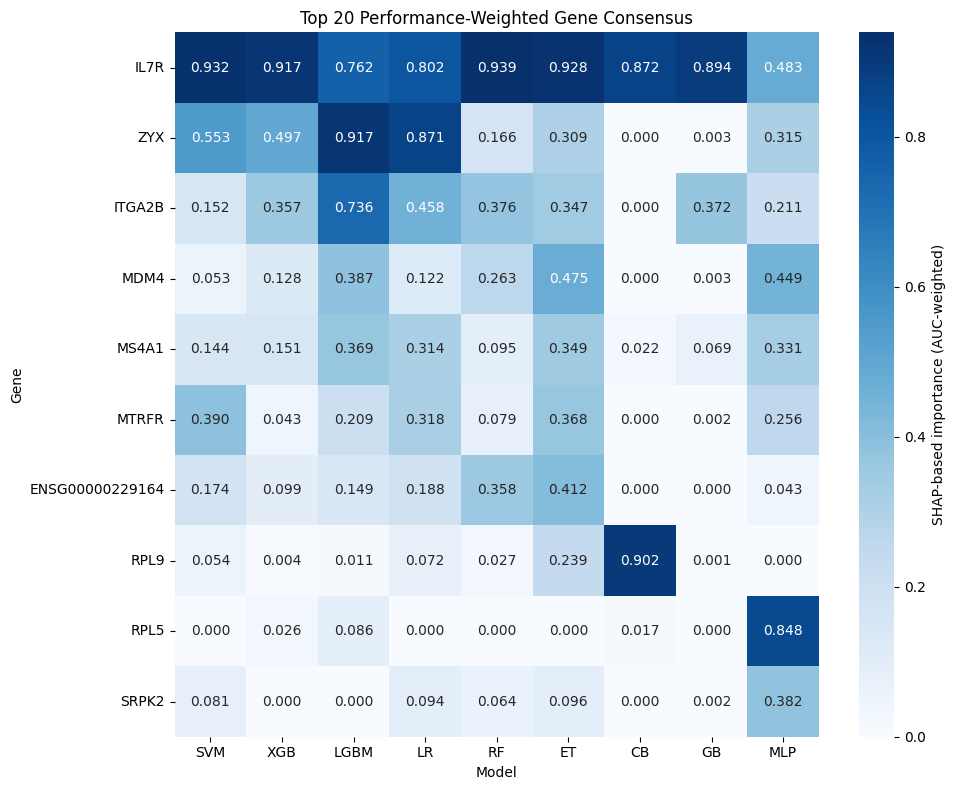

In [18]:
# ── Build dataframe (genes × models) ────────────────────────────────────────
df_shap = pd.DataFrame(shap_importance, index=feat_names)

# ── Weight each model column by its test AUC at this feature count ─────────
auc_weights = {}
for n in MODEL_NAMES:
    col = f"AUC_{n}"
    if col in best_test:
        auc_weights[n] = float(str(best_test[col]).rstrip("%")) / 100.0

df_shap_weighted = df_shap.mul(pd.Series(auc_weights))

# ── Sort genes by overall consensus ────────────────────────────────────────
df_shap_weighted["__total__"] = df_shap_weighted.sum(axis=1)
# Create a sorted dataframe
df_sorted = df_shap_weighted.sort_values("__total__", ascending=False)

# ── Filter to top 20 genes ────────────────────────────────────────────────
df_top20 = df_sorted.head(10).drop(columns="__total__")

# ── Plot ───────────────────────────────────────────────────────────────────
# ── Plot with annotations ──────────────────────────────────────────────────
plt.figure(figsize=(10, 8)) # Slightly wider to accommodate labels
sns.heatmap(
    df_top20,
    annot=True,              # This adds the numbers to the rectangles
    fmt=".3f",               # Formats the numbers to 3 decimal places
    cmap="Blues",
    vmin=0,
    vmax=df_shap_weighted.drop(columns="__total__").values.max(),
    cbar_kws={"label": "SHAP-based importance (AUC-weighted)"}
)

plt.title("Top 20 Performance-Weighted Gene Consensus")
plt.xlabel("Model")
plt.ylabel("Gene")
plt.tight_layout()
plt.show()